# Lab 9

## Name: Abdulsamad Mousa Tuhaishi
## ID: 2240001093


In [ ]:
# importing the libraries we need
import cv2          # for image processing
import numpy as np  # for arrays and math
import matplotlib.pyplot as plt  # for showing images

# the image file we will work with
imgFile = 'Balls.png'

# **Task 1**

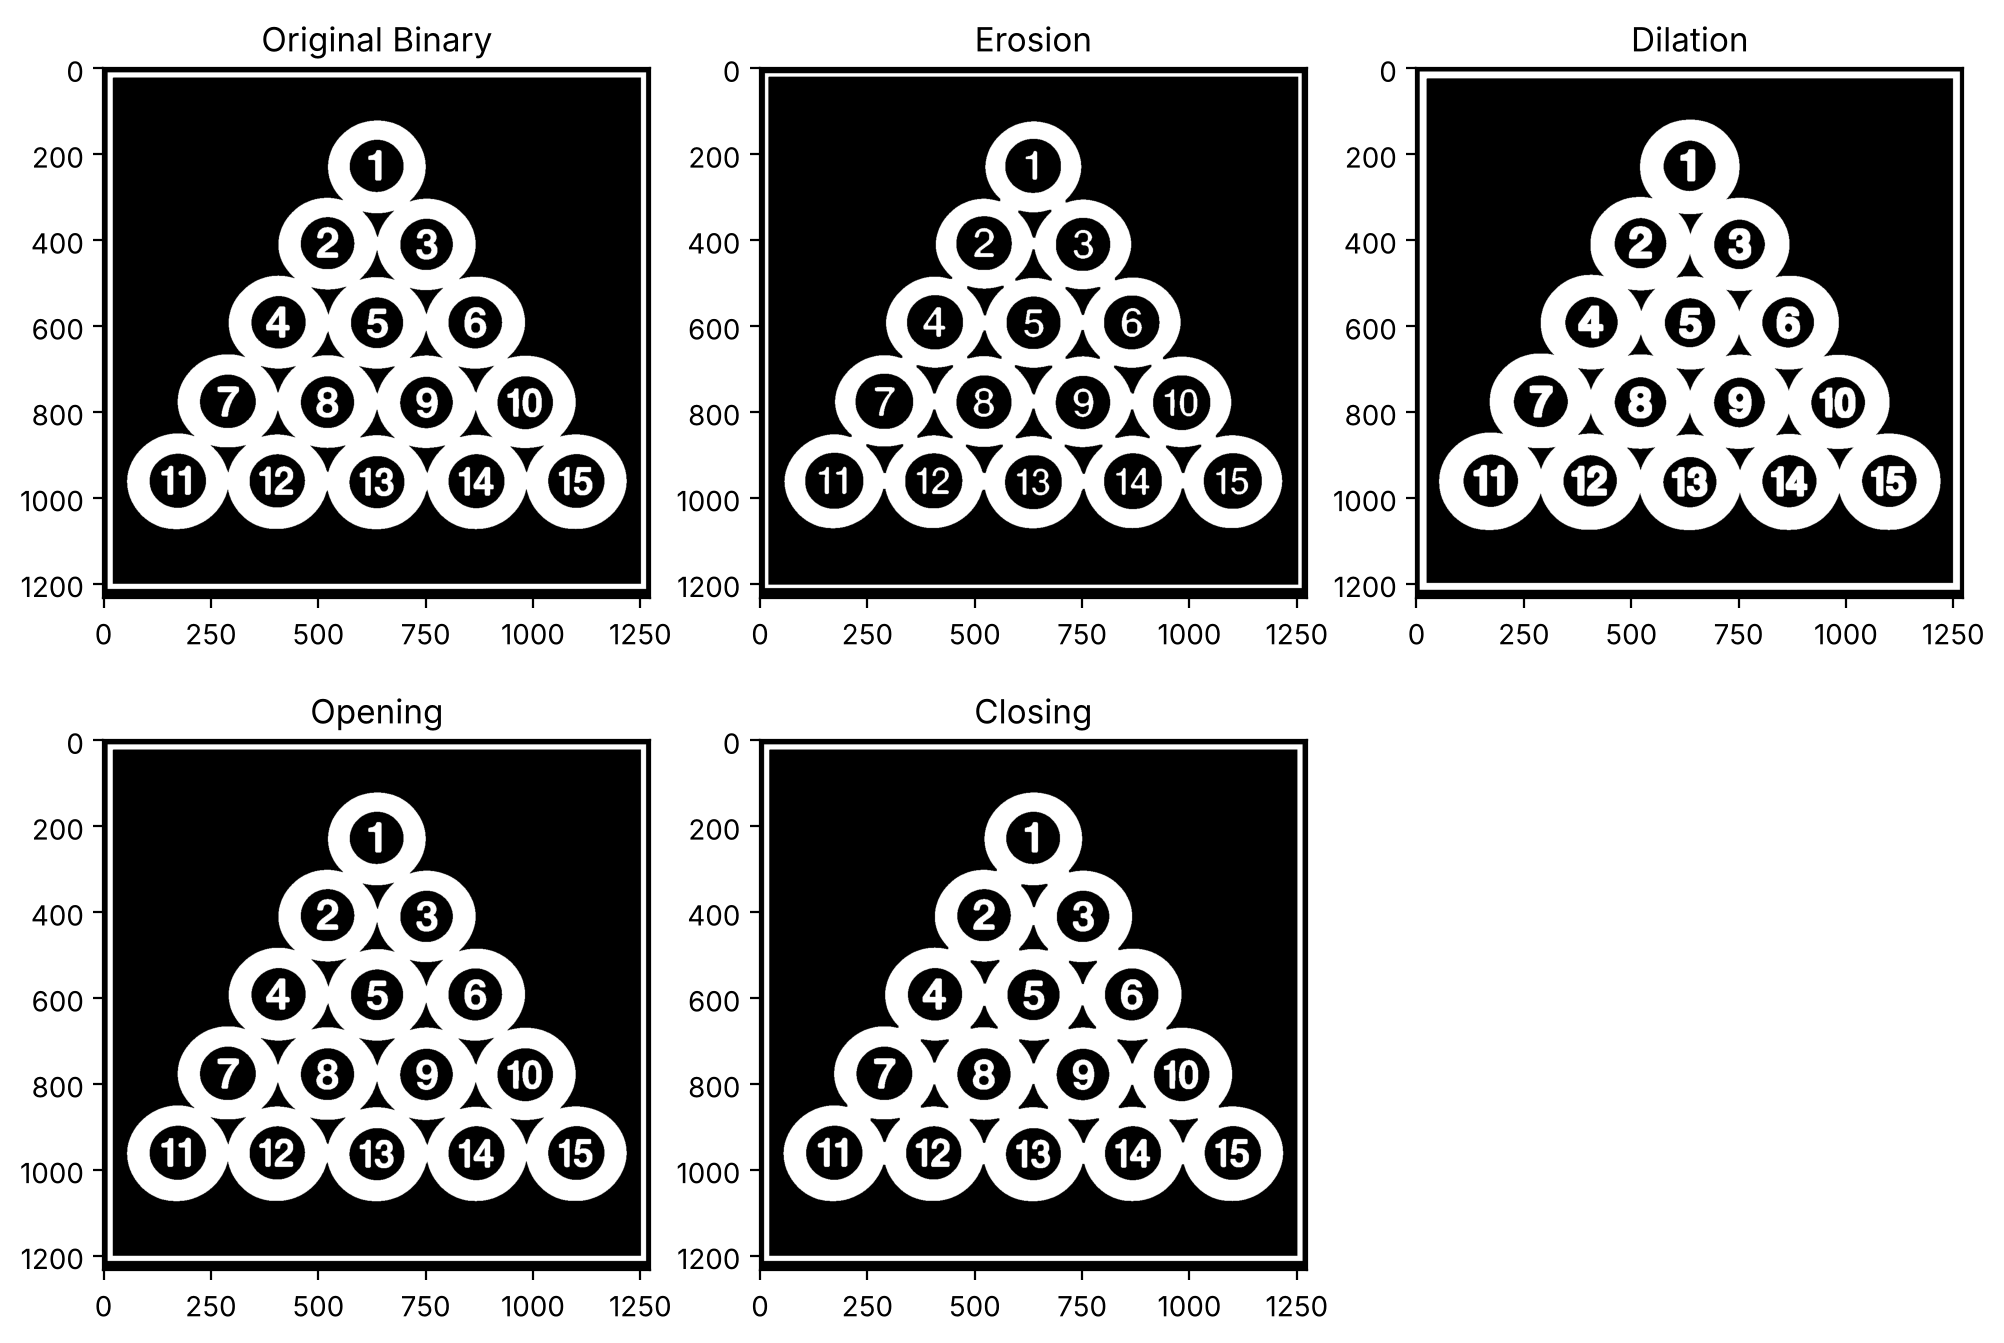

In [2]:
# read the image in grayscale
img = cv2.imread(imgFile, 0)

# convert to binary using Otsu's method
# using BINARY_INV because the balls are dark, so we invert to make them white
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# create a 5x5 square kernel for the morphological operations
kernel = np.ones((5, 5), np.uint8)

# apply the four basic morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)   # shrinks white regions
dilation = cv2.dilate(binary, kernel, iterations=1)  # grows white regions
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)   # erosion then dilation (removes small noise)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)  # dilation then erosion (fills small holes)

# display all results side by side
plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 3, 2), plt.imshow(erosion, 'gray'), plt.title('Erosion')
plt.subplot(2, 3, 3), plt.imshow(dilation, 'gray'), plt.title('Dilation')
plt.subplot(2, 3, 4), plt.imshow(opening, 'gray'), plt.title('Opening')
plt.subplot(2, 3, 5), plt.imshow(closing, 'gray'), plt.title('Closing')
plt.show()

**Observations**
- Erosion makes the white balls smaller and the white numbers thinner.
- Dilation makes the balls bigger, so they start to touch each other, and the numbers get thicker.
- Opening removes small white details and keeps the balls almost the same size.
- Closing fills small black gaps (the small spaces between the balls and inside the numbers).

# **Task 2**

## Different shapes (kernel size 7x7)

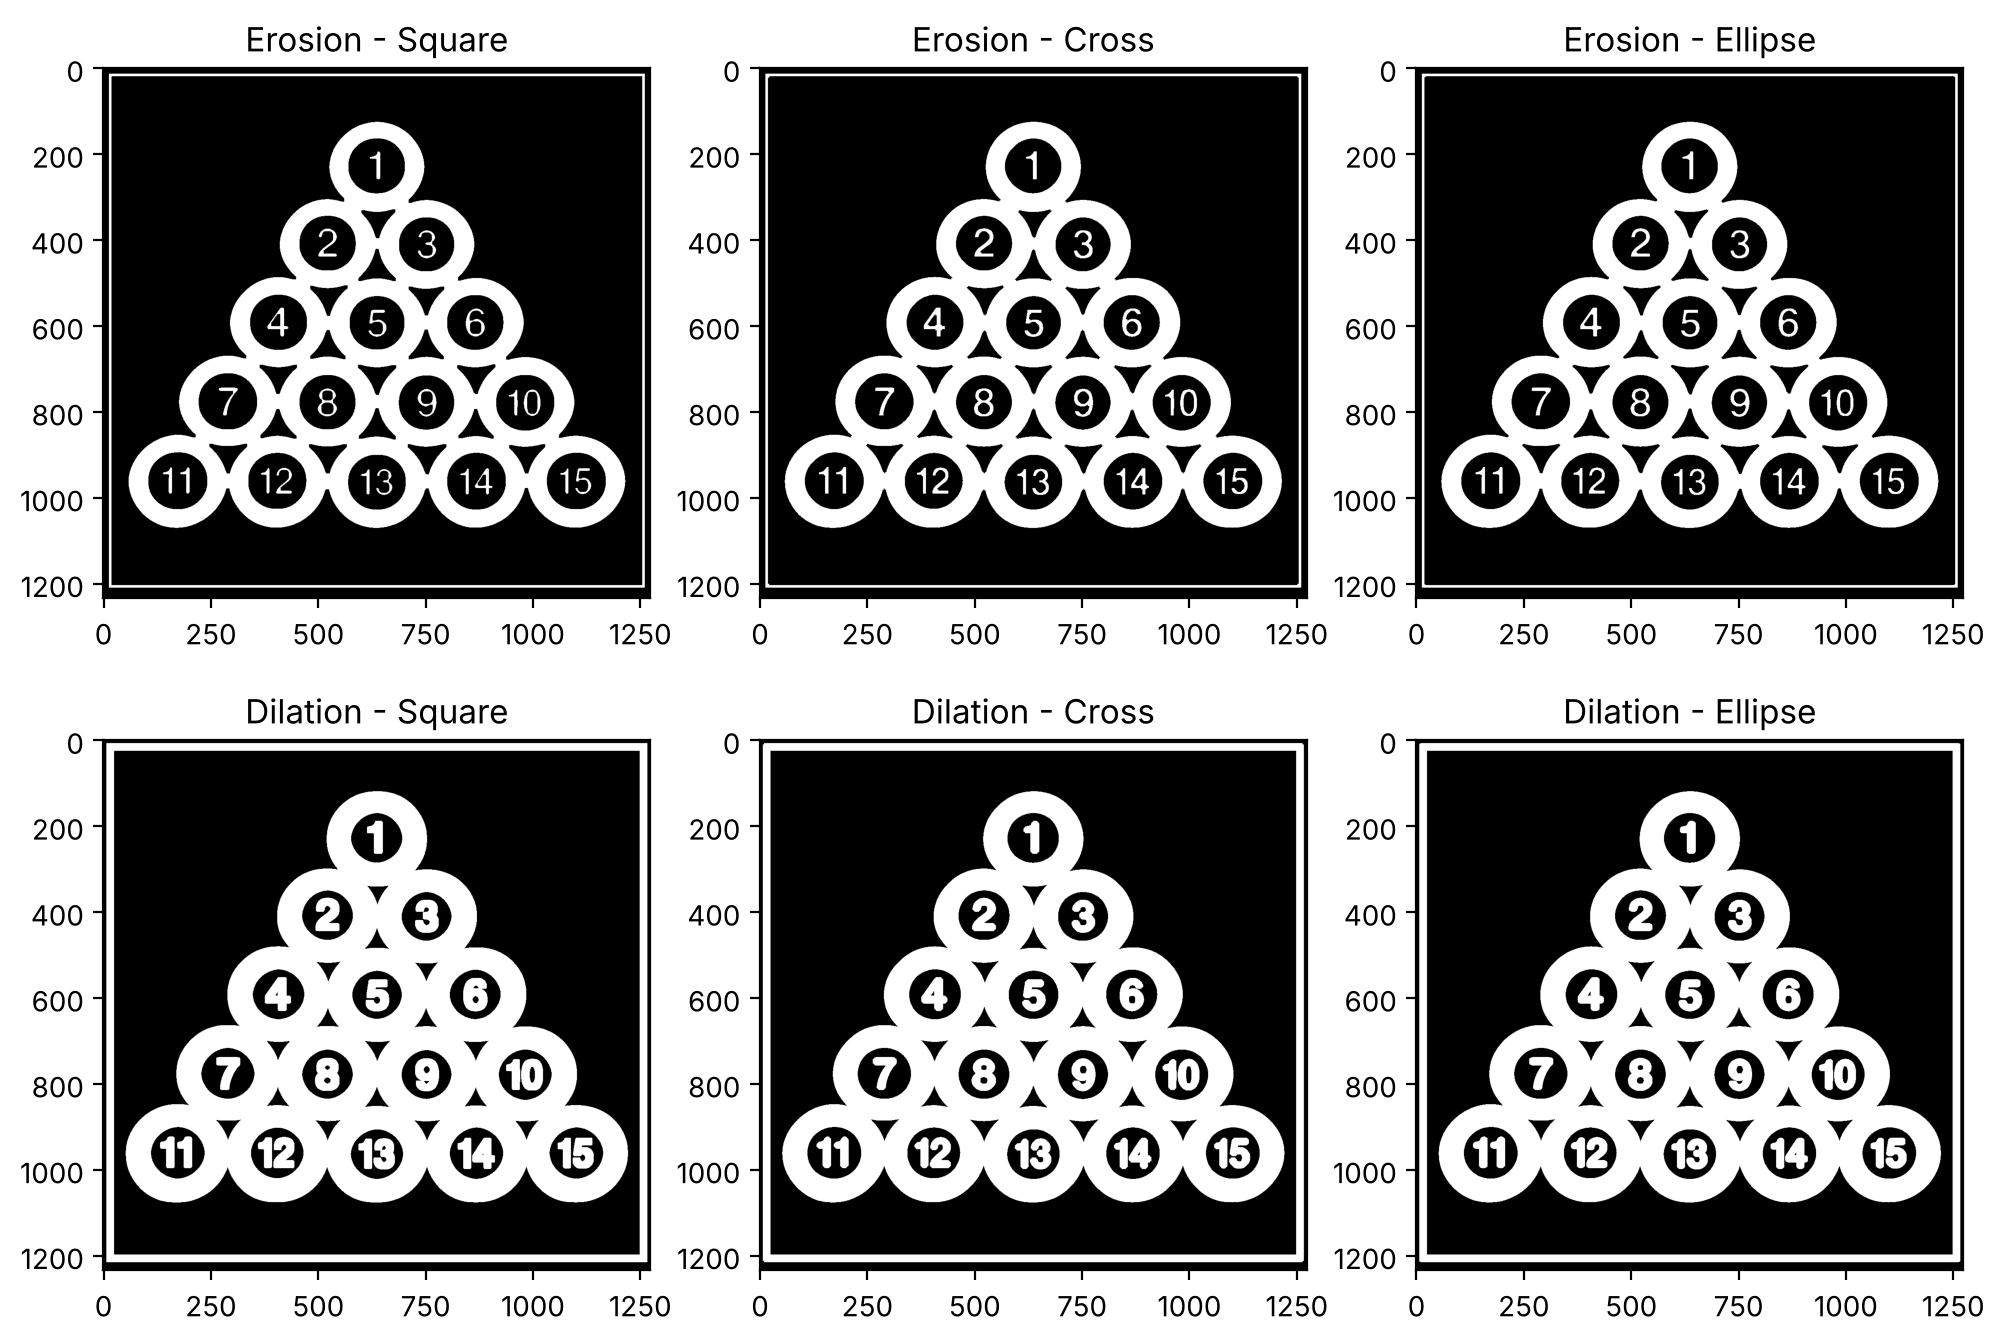

In [3]:
# create three different shaped kernels, all 7x7
rect = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))      # square shape
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))     # cross / plus shape
ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)) # round / ellipse shape

# put them in lists so we can loop
kernels = [rect, cross, ellipse]
names = ['Square', 'Cross', 'Ellipse']

# show erosion and dilation for each kernel shape
plt.figure(figsize=(12, 8))
for i in range(3):
    # top row = erosion
    plt.subplot(2, 3, i+1)
    plt.imshow(cv2.erode(binary, kernels[i]), 'gray')
    plt.title('Erosion - ' + names[i])
    # bottom row = dilation
    plt.subplot(2, 3, i+4)
    plt.imshow(cv2.dilate(binary, kernels[i]), 'gray')
    plt.title('Dilation - ' + names[i])
plt.show()

## Different sizes (3x3, 5x5, 7x7) with square kernel

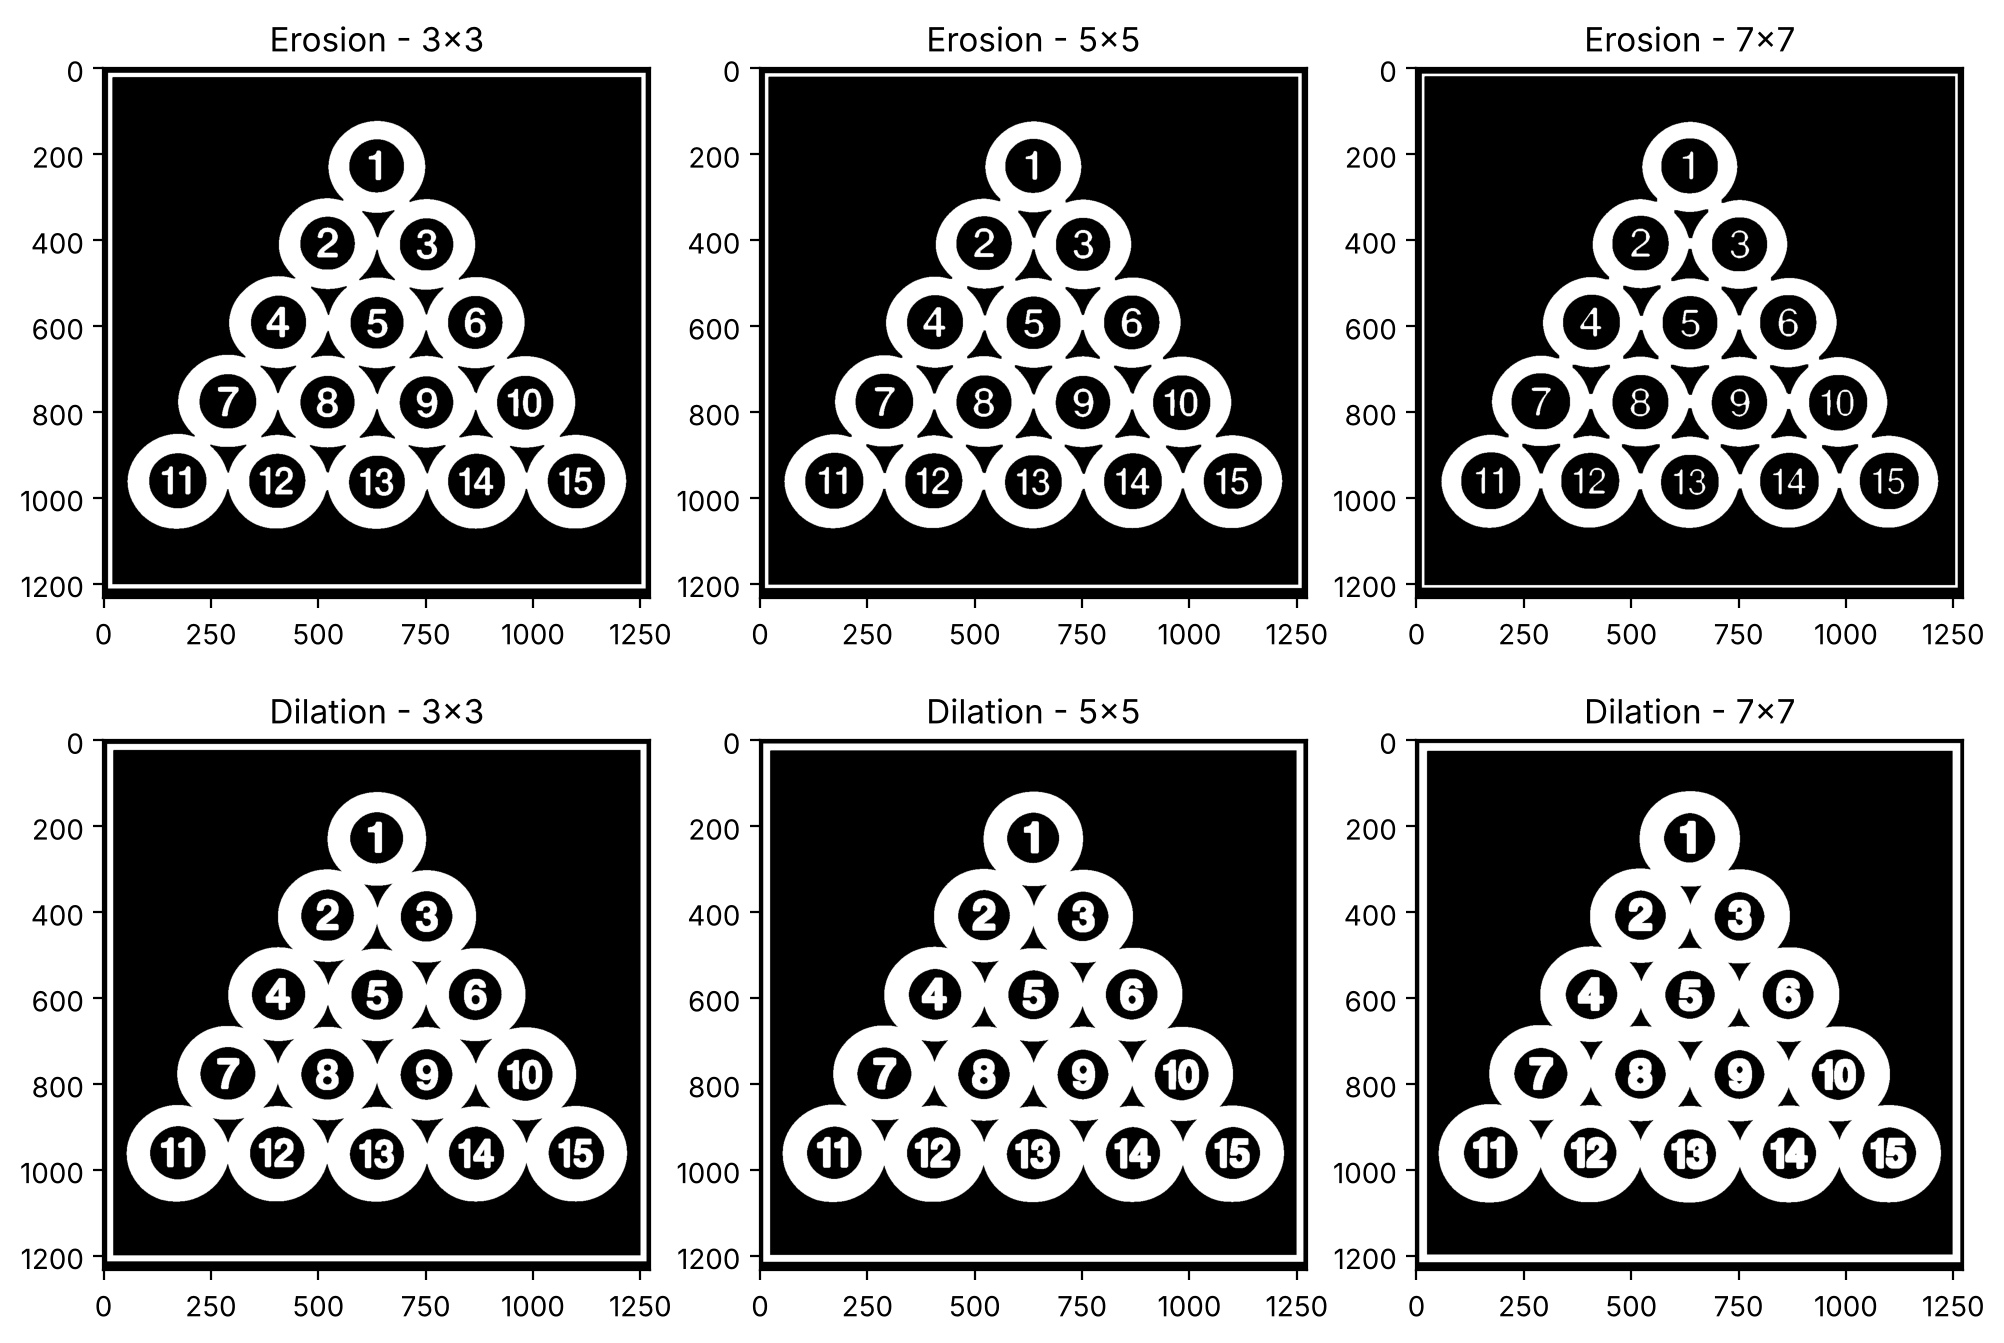

In [4]:
# try three different kernel sizes: small, medium, large
sizes = [3, 5, 7]

plt.figure(figsize=(12, 8))
for i in range(3):
    # make a square kernel of the current size
    k = np.ones((sizes[i], sizes[i]), np.uint8)
    # top row = erosion with this size
    plt.subplot(2, 3, i+1)
    plt.imshow(cv2.erode(binary, k), 'gray')
    plt.title('Erosion - %dx%d' % (sizes[i], sizes[i]))
    # bottom row = dilation with this size
    plt.subplot(2, 3, i+4)
    plt.imshow(cv2.dilate(binary, k), 'gray')
    plt.title('Dilation - %dx%d' % (sizes[i], sizes[i]))
plt.show()

**Comparison**
- Square kernel: changes the image the most and makes the edges look blocky.
- Cross kernel: changes the image the least and keeps the shape of the balls smooth.
- Ellipse kernel: gives rounder results, which fits the circle shape of the balls.
- Bigger kernel size (3x3 -> 7x7): erosion shrinks more and dilation grows more, so with 7x7 the balls almost merge together and the numbers can disappear.